## MapleFreight Delivery Delay Prediction

## 1. Business Context

MapleFreight Logistics moves about 8,000 shipments a week across Ontario, Quebec and the Prairies. Its contracts carry on-time guarantees, so every late delivery costs service credits and re-delivery charges.

On-time performance has dropped from 94% to 88% this year, and we only learn a shipment is late when the customer calls.

## 2. Problem Statement

You are a Data Scientist at MapleFreight. Delays are currently found only after the delivery window has passed, which means paid-out service credits, expedited re-deliveries and complaints that reach the account manager before dispatch knows anything is wrong.

Build an end-to-end system that predicts which in-transit shipments will arrive late and alerts dispatch in Slack while there is still time to re-route or warn the customer.

## 3. Objectives
1. Analyze shipment, route and carrier data to identify the main drivers of late delivery.
2. Build a predictive model that classifies whether a shipment will be delivered late.
3. Integrate Slack alerts so dispatch is notified about high-risk shipments automatically.
4. Provide actionable recommendations that improve on-time performance.

## 4. Data Understanding

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("maplefreight_delivery_delay_dataset.csv")
df.head(10)

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0
5,SHP-101857,Montreal QC,Winnipeg MB,Contract Owner-Op,Express,General Freight,Gold,10,572.7,1310.8,...,53.0,3.7,5.3,Storm,72.9,0.467,4,149.19,10.00,1
6,SHP-102142,Toronto ON,Toronto ON,QuebecExpress,Economy,General Freight,Silver,6,303.3,1259.5,...,-5.0,4.5,3.2,Clear,65.2,0.514,0,133.83,5.32,0
7,SHP-103123,Mississauga ON,Winnipeg MB,NorthStar Carriers,Standard,General Freight,Gold,1,776.6,1043.6,...,9.0,4.9,4.2,NaN,58.9,0.586,0,180.57,11.60,0
8,SHP-100691,Mississauga ON,Quebec City QC,PrairieLine,Express,General Freight,Silver,9,755.4,889.2,...,25.0,2.3,4.7,Clear,54.4,0.330,1,150.68,10.77,0
9,SHP-101694,London ON,Regina SK,MapleFreight Fleet,Express,Fragile,Silver,9,172.7,1322.8,...,38.0,10.2,2.4,Clear,63.6,0.778,1,124.74,3.26,0


In [7]:
df.shape

(6035, 23)

In [8]:
df.describe()

,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
count,6035.000000,6035.000000,6.035000e+03,6035.000000,6035.000000,6035.000000,6035.000000,5825.000000,6035.000000,5914.000000,6035.000000,6035.000000,5795.000000,6035.000000,6035.000000
mean,6.543662,632.192742,6.928251e+03,2.477051,0.113007,10.500388,20.367688,6.497648,5.489461,55.146365,0.449778,1.305551,180.696552,11.186038,0.205800
std,3.448260,319.246133,8.375515e+04,1.707457,0.316628,4.758576,30.618617,4.659277,3.433676,17.592978,0.194500,1.158943,58.759928,5.957114,0.404318
min,1.000000,80.500000,3.000000e+01,0.000000,0.000000,1.000000,-20.000000,0.200000,0.100000,5.000000,0.000000,0.000000,30.000000,0.880000,0.000000
25%,4.000000,398.600000,4.960000e+02,1.000000,0.000000,7.060000,-6.000000,3.200000,3.000000,43.300000,0.318000,0.000000,140.595000,7.080000,0.000000
50%,7.000000,571.100000,8.271000e+02,2.000000,0.000000,9.850000,18.000000,5.400000,4.800000,55.000000,0.446000,1.000000,181.180000,10.050000,0.000000
75%,10.000000,804.850000,1.286300e+03,4.000000,0.000000,13.175000,41.000000,8.600000,7.200000,67.200000,0.583000,2.000000,220.950000,14.010000,0.000000
max,12.000000,2556.700000,2.999300e+06,5.000000,1.000000,37.400000,146.000000,35.000000,20.000000,100.000000,1.000000,8.000000,392.010000,55.380000,1.000000


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

## 5. Exploratory data analysis (EDA)

In [10]:
df['delivered_late'].value_counts(normalize=True)*100

delivered_late
0    79.42005
1    20.57995
Name: proportion, dtype: float64

The target variable (delivered_late) shows that approximately 21% of shipments are late, while the remaining 79% are on time. This means that the dataset is unbalanced and this could affect the model

In [11]:
df['carrier'].value_counts()

carrier
MapleFreight Fleet    2391
NorthStar Carriers    1164
PrairieLine            932
QuebecExpress          924
Contract Owner-Op      624
Name: count, dtype: int64

In [12]:
df['service_level'].value_counts()

service_level
Standard    3219
Express     1442
Economy     1254
standard      74
express       27
economy       19
Name: count, dtype: int64

Different category labels might cause the model to handle equivalent categories as different groups, so this can negatively impact its ability to generalize to new data.

In [13]:
df['fuel_cost_cad'].head(20)

0     146.39
1     155.07
2     163.44
3        NaN
4     263.22
5     149.19
6     133.83
7     180.57
8     150.68
9     124.74
10    251.70
11    180.59
12    175.71
13     94.62
14    136.76
15    186.15
16    172.79
17    130.69
18    214.07
19    285.06
Name: fuel_cost_cad, dtype: float64

In [14]:
#identify the duplicates
df[df.duplicated()]

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
932,SHP-100457,Montreal QC,Toronto ON,PrairieLine,Economy,General Freight,Silver,8,532.1,1113.3,...,26.0,20.2,4.6,Clear,66.3,0.691,0,115.19,8.49,0
1443,SHP-103447,Toronto ON,Calgary AB,MapleFreight Fleet,Standard,Bulk,Bronze,11,430.5,1018.4,...,5.0,4.9,9.3,Snow,24.2,0.468,3,106.86,10.49,0
2453,SHP-104541,London ON,Ottawa ON,NorthStar Carriers,Standard,General Freight,Gold,11,608.8,637.0,...,-1.0,3.1,3.8,Clear,62.7,0.441,1,193.43,8.97,0
2599,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,Economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
2920,SHP-101174,London ON,Edmonton AB,MapleFreight Fleet,Standard,Refrigerated,Bronze,4,348.2,883.6,...,6.0,12.8,3.1,Clear,65.3,0.420,1,208.64,4.82,0
2956,SHP-103516,Toronto ON,Sudbury ON,PrairieLine,Express,General Freight,Gold,10,215.3,603.7,...,9.0,6.1,5.0,Rain,79.3,0.600,1,211.34,7.80,1
3135,SHP-104402,Winnipeg MB,Sudbury ON,NorthStar Carriers,Express,Refrigerated,Bronze,7,855.0,1098.4,...,-20.0,3.1,4.4,Storm,NaN,0.713,1,152.77,14.64,0
3184,SHP-101699,Toronto ON,Quebec City QC,QuebecExpress,Express,General Freight,Bronze,9,523.3,775.9,...,30.0,10.6,5.5,Clear,75.7,0.636,1,239.41,9.88,0
3188,SHP-105617,Toronto ON,Quebec City QC,MapleFreight Fleet,Standard,General Freight,Silver,12,465.2,928.4,...,4.0,3.8,3.8,Fog,69.2,0.612,1,197.80,9.61,0
3583,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,Economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0


We have 32 duplicates rows

In [15]:
#verify if in any other string column there is an inconsistency
for col in df.select_dtypes(include='object').columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- shipment_id ---
shipment_id
SHP-102224    2
SHP-100457    2
SHP-104541    2
SHP-103447    2
SHP-105761    2
             ..
SHP-101294    1
SHP-104024    1
SHP-105201    1
SHP-103776    1
SHP-101946    1
Name: count, Length: 6000, dtype: int64

--- origin_city ---
origin_city
Toronto ON        1593
Mississauga ON    1019
Montreal QC       1017
Calgary AB         762
Ottawa ON          730
London ON          460
Winnipeg MB        454
Name: count, dtype: int64

--- destination_city ---
destination_city
Sudbury ON        641
Toronto ON        638
Regina SK         634
Winnipeg MB       614
Hamilton ON       604
Quebec City QC    598
Edmonton AB       592
Montreal QC       587
Calgary AB        578
Ottawa ON         549
Name: count, dtype: int64

--- carrier ---
carrier
MapleFreight Fleet    2391
NorthStar Carriers    1164
PrairieLine            932
QuebecExpress          924
Contract Owner-Op      624
Name: count, dtype: int64

--- service_level ---
service_level
Standard    3219
Ex

C:\Users\LILIP\AppData\Local\Temp\ipykernel_42368\3435845938.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


We are verifying if in any other string column have an inconsistency to fix it before processing the data

In [16]:
#The verification by column let me know that for the shipment_id there is 6000 unique values but we have 6035 raws, so we need to investigate if they are duplicate or something else
df['shipment_id'].duplicated().sum()

np.int64(35)

Is a good practice to verify the timestamps, identificators or secondaty fields since it may vary but could represent the same event.

In [17]:
#Verify if the duplicates contains the same information ordered by shipment_id, since we have 35
df[df['shipment_id'].duplicated(keep=False)].sort_values('shipment_id')

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
1921,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,Economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0
3583,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,Economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0
2599,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,Economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
867,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,Economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
4115,SHP-100063,Ottawa ON,Quebec City QC,MapleFreight Fleet,Standard,Hazardous,Bronze,6,1255.7,844.8,...,48.0,4.3,11.4,Clear,41.9,0.338,1,211.74,20.18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2198,SHP-105433,Toronto ON,Ottawa ON,QuebecExpress,Express,General Freight,Silver,12,935.7,999.0,...,7.0,9.8,1.6,Rain,53.4,0.369,2,117.48,15.33,0
702,SHP-105617,Toronto ON,Quebec City QC,MapleFreight Fleet,Standard,General Freight,Silver,12,465.2,928.4,...,4.0,3.8,3.8,Fog,69.2,0.612,1,197.80,9.61,0
3188,SHP-105617,Toronto ON,Quebec City QC,MapleFreight Fleet,Standard,General Freight,Silver,12,465.2,928.4,...,4.0,3.8,3.8,Fog,69.2,0.612,1,197.80,9.61,0
307,SHP-105761,Mississauga ON,Montreal QC,NorthStar Carriers,Standard,Refrigerated,Bronze,6,303.7,68.9,...,31.0,8.0,2.5,Clear,43.0,0.723,1,235.19,11.98,1


The dataset contains 32 additional duplicate rows, but also we found that there are 35 duplicates for shipment_id that probably include those 32 duplicates, before removing them will be better to investigate if they are exactly the same since keeping them may give duplicated observations more influence during model training and may lead to data leakage between the training and test sets.

In [18]:
# Count missing values in a specific column
df.isna().sum()

shipment_id                    0
origin_city                    0
destination_city               0
carrier                        0
service_level                  0
goods_type                     0
customer_priority_tier         0
shipment_month                 0
distance_km                    0
weight_kg                      0
num_stops                      0
is_cross_border                0
scheduled_transit_hours        0
pickup_delay_minutes           0
driver_experience_years      210
vehicle_age_years              0
weather_condition            150
traffic_index                121
route_congestion_score         0
prior_late_deliveries_30d      0
fuel_cost_cad                240
actual_transit_hours           0
delivered_late                 0
dtype: int64

We have missing data in the fields: driver_experience_years, weather_condition, traffic_index and fuel_cost_cad

In [19]:
#Ho much does missing values represent vs the total data
round((df.isna().sum())/df.__len__()*100,1)

shipment_id                  0.0
origin_city                  0.0
destination_city             0.0
carrier                      0.0
service_level                0.0
goods_type                   0.0
customer_priority_tier       0.0
shipment_month               0.0
distance_km                  0.0
weight_kg                    0.0
num_stops                    0.0
is_cross_border              0.0
scheduled_transit_hours      0.0
pickup_delay_minutes         0.0
driver_experience_years      3.5
vehicle_age_years            0.0
weather_condition            2.5
traffic_index                2.0
route_congestion_score       0.0
prior_late_deliveries_30d    0.0
fuel_cost_cad                4.0
actual_transit_hours         0.0
delivered_late               0.0
dtype: float64

We can se how much they represents vs the total of the data, to determine if its better to keep or remove them

In [20]:
for col in df.select_dtypes(include='float').columns:
    ng= df[col] < 0
    print(f"{col}: {ng.sum()}")

distance_km: 0
weight_kg: 0
scheduled_transit_hours: 0
pickup_delay_minutes: 1794
driver_experience_years: 0
vehicle_age_years: 0
traffic_index: 0
route_congestion_score: 0
fuel_cost_cad: 0
actual_transit_hours: 0


Pickup_delay_minutes contains 1,794 negative values, while the other numerical variables does not. These values should be investigated before being hanlde as erros cause negative pickup delays may represent pickups happening earlier than scheduled.

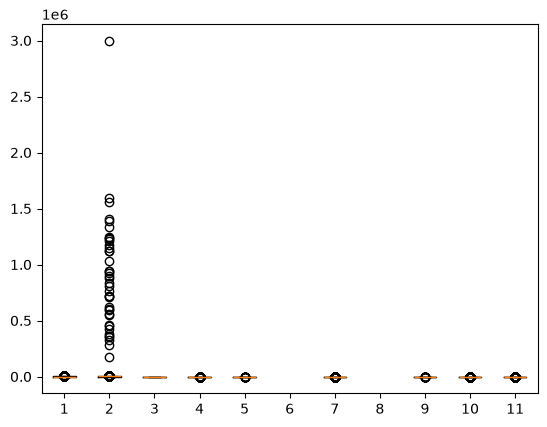

In [21]:
#Identifying possible outliers
numeric_cols = [    
    'distance_km',
    'weight_kg',
    'num_stops',
    'scheduled_transit_hours',
    'pickup_delay_minutes',
    'driver_experience_years',
    'vehicle_age_years',
    'traffic_index',
    'route_congestion_score',
    'actual_transit_hours',
    'delivered_late'
]

plt.boxplot(df[numeric_cols])
plt.show()

With the boxplot applied for all the numeric values, we could identified possible outliers, especially for the weight_km field, which has a lot of them an a particular one very spread from the others.

In [22]:
#Correlation between variables
corr_matrix = df[numeric_cols].corr()
corr_matrix

,distance_km,weight_kg,num_stops,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,actual_transit_hours,delivered_late
distance_km,1.000000,-0.005970,0.020543,0.933420,0.006818,-0.020607,-0.009682,-0.010533,-0.013285,0.867228,0.184147
weight_kg,-0.005970,1.000000,0.009346,-0.006832,-0.001608,-0.028718,-0.005659,0.011537,0.029502,0.002718,0.007913
num_stops,0.020543,0.009346,1.000000,0.273931,-0.011493,-0.021076,0.001553,0.017281,-0.012844,0.270844,0.154480
scheduled_transit_hours,0.933420,-0.006832,0.273931,1.000000,0.005144,-0.021473,-0.013881,-0.000267,-0.015565,0.926491,0.208301
pickup_delay_minutes,0.006818,-0.001608,-0.011493,0.005144,1.000000,-0.002497,-0.004070,0.023045,-0.004378,0.045064,0.127249
driver_experience_years,-0.020607,-0.028718,-0.021076,-0.021473,-0.002497,1.000000,-0.011110,-0.011370,-0.022254,-0.046630,-0.091598
vehicle_age_years,-0.009682,-0.005659,0.001553,-0.013881,-0.004070,-0.011110,1.000000,0.004421,0.003788,0.012973,0.062575
traffic_index,-0.010533,0.011537,0.017281,-0.000267,0.023045,-0.011370,0.004421,1.000000,-0.006423,0.048005,0.166187
route_congestion_score,-0.013285,0.029502,-0.012844,-0.015565,-0.004378,-0.022254,0.003788,-0.006423,1.000000,0.019831,0.100448
actual_transit_hours,0.867228,0.002718,0.270844,0.926491,0.045064,-0.046630,0.012973,0.048005,0.019831,1.000000,0.493526


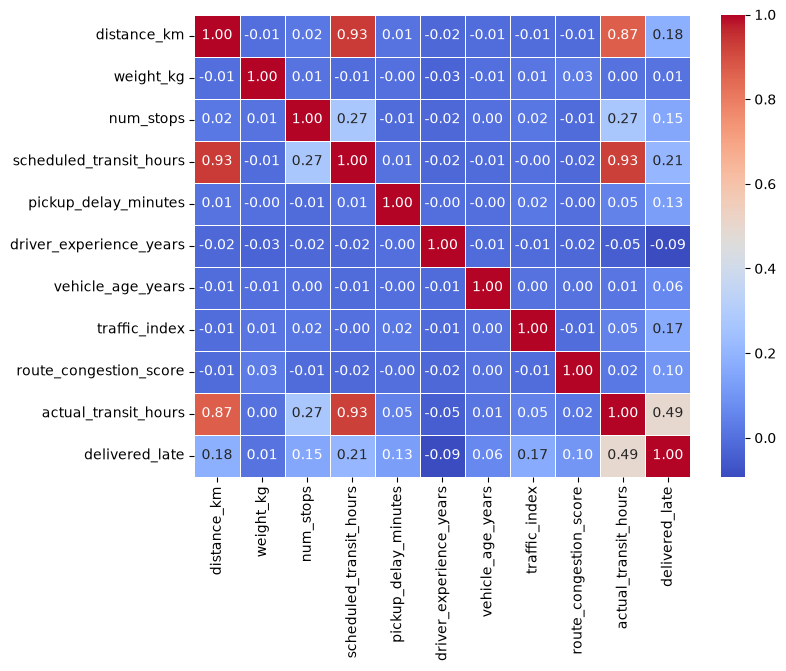

In [23]:
import seaborn as sns
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,  # Muestra los valores numéricos dentro de las celdas
    cmap="coolwarm",  # Paleta de colores (azul para negativo, rojo para positivo)
    fmt=".2f",  # Limita los decimales a 2
    linewidths=0.5,  # Líneas divisorias entre celdas
)


plt.show()

With the headmap we can see how strong are related the features between each other. We can see that distance has a strong relation with delivered_late with 0.18 as well as num_stops with 0.15, traffic_index with 0.17 and pickup_delays with 0.13, this should be consider as possible candidates features that can impact the model

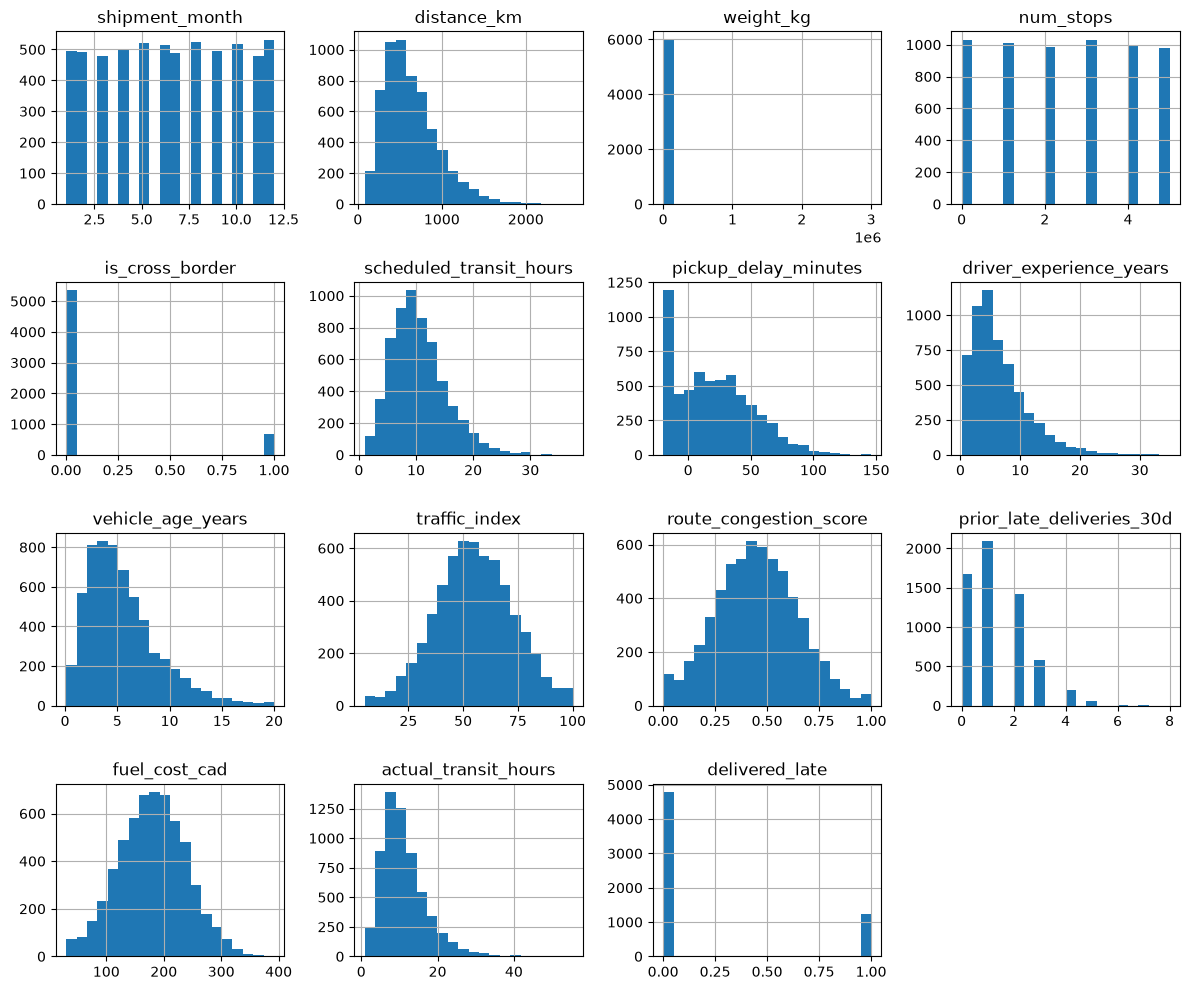

In [24]:
#Identify the distributions
df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

With this graph, we can see the distribution for each feature to see handle the missing values and identify potential outliers

## 6. Data preprocessing

In [ ]:
#Stadarize the service level category
service_level_map = {
    'Standard' : 'Standard',
    'standard' : 'Standard',
    'Economy' : 'Economy',
    'economy' : 'Economy',
    'Express' : 'Express',
    'express' : 'Express'
}

df['service_level'] = df['service_level'].map(service_level_map)
df['service_level'].value_counts()

service_level
Standard    3293
Express     1469
Economy     1273
Name: count, dtype: int64

Stadarize the service level category helps to prevent that the model handle the same category as different

In [26]:
#removing the duplicates
#df.drop_duplicates(keep='first')

In [27]:
#Remove the duplicates for id
df = df.drop_duplicates(subset=['shipment_id'], keep='first') #keeping the firts appareance

In [28]:
#confirm that were indeed remove
df['shipment_id'].duplicated().sum()

np.int64(0)

We confirmed that there are zero duplicates

In [29]:
df[df.duplicated()]

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late


In [30]:
df.columns

Index(['shipment_id', 'origin_city', 'destination_city', 'carrier',
       'service_level', 'goods_type', 'customer_priority_tier',
       'shipment_month', 'distance_km', 'weight_kg', 'num_stops',
       'is_cross_border', 'scheduled_transit_hours', 'pickup_delay_minutes',
       'driver_experience_years', 'vehicle_age_years', 'weather_condition',
       'traffic_index', 'route_congestion_score', 'prior_late_deliveries_30d',
       'fuel_cost_cad', 'actual_transit_hours', 'delivered_late'],
      dtype='str')

In [31]:
#Handle missing values
#driver_experience -> median
df['driver_experience_years'] = df['driver_experience_years'].fillna(df['driver_experience_years'].median())
#weather -> mode
df['weather_condition'] = df['weather_condition'].fillna(df['weather_condition'].mode()[0])
#Traffic -> mean
df['traffic_index'] = df['traffic_index'].fillna(df['traffic_index'].median())
#fuel -> mean
df['fuel_cost_cad'] = df['fuel_cost_cad'].fillna(df['fuel_cost_cad'].median())

We handle the missing values with imputation instead of omissing despite of the low amount of them vs the whole data since it can have meaningful information that can impact the model, we handle them according with their distribution and type of variable

In [32]:
df.isnull().mean() * 100

shipment_id                  0.0
origin_city                  0.0
destination_city             0.0
carrier                      0.0
service_level                0.0
goods_type                   0.0
customer_priority_tier       0.0
shipment_month               0.0
distance_km                  0.0
weight_kg                    0.0
num_stops                    0.0
is_cross_border              0.0
scheduled_transit_hours      0.0
pickup_delay_minutes         0.0
driver_experience_years      0.0
vehicle_age_years            0.0
weather_condition            0.0
traffic_index                0.0
route_congestion_score       0.0
prior_late_deliveries_30d    0.0
fuel_cost_cad                0.0
actual_transit_hours         0.0
delivered_late               0.0
dtype: float64

We check if there still missing values, in this case not

{'whiskers': [<matplotlib.lines.Line2D at 0x1770bebfe00>,
 'caps': [<matplotlib.lines.Line2D at 0x1770bf441a0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1770bebfcb0>],
 'medians': [<matplotlib.lines.Line2D at 0x1770bf44440>],
 'fliers': [<matplotlib.lines.Line2D at 0x1770bf44590>],
 'means': []}

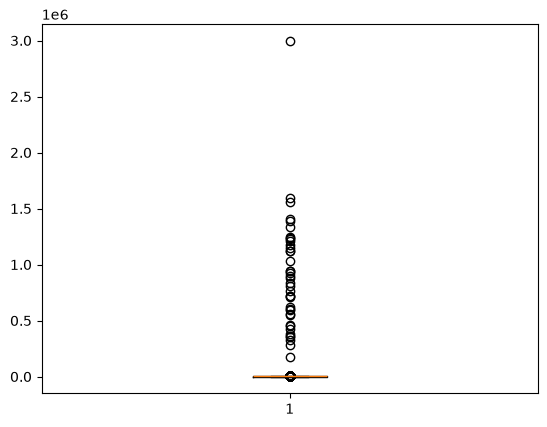

In [33]:
#Visualizing the outliers for weight_kg
plt.boxplot(df['weight_kg'])

We previously identified that the weight_kg had outliers, now we are grapghing it alone to see it more clearly, where we can see that have a lot number of outliers but there is one in particular far way from the others

In [34]:
#outiers handling
Q1 = df['weight_kg'].quantile(0.25)
Q3 = df['weight_kg'].quantile(0.75)
IQR = Q3 - Q1
print(f'Q1:', Q1)
print(f'Q3:', Q3)
print(f'IQR:', IQR)

upper_limit_weight = Q3 + 1.5 * IQR
print(f'Upper Limit (weight_kg): {upper_limit_weight}')

lower_limit_weight = Q1 - 1.5 * IQR
print(f'Lower Limit (weight_kg): {lower_limit_weight}')
print(f'Median:', {df['weight_kg'].median()})

Q1: 495.975
Q3: 1286.75
IQR: 790.775
Upper Limit (weight_kg): 2472.9125
Lower Limit (weight_kg): -690.1874999999999
Median: {np.float64(827.1)}


In [124]:
(df['weight_kg'] > upper_limit_weight).sum()

np.int64(187)

We calculate the IQR to see the limits of the ouliers and capping them in order to not lose valuable information. We can see that we have 187 outliers in this dataset

In [35]:
#capping the outliers for weight_kg, 
df['weight_capped'] = df['weight_kg'].clip(lower=-690.1874999999999, upper=2472.9125) #Reemplazar valores fuera de rango por los límites

Replace the outliers with the limits range calculate before

In [36]:
df['weight_capped'].describe()

count    6000.000000
mean      953.325006
std       594.555151
min        30.000000
25%       495.975000
50%       827.100000
75%      1286.750000
max      2472.912500
Name: weight_capped, dtype: float64

In [ ]:
df['weight_log_capped'] = np.log1p(df['weight_capped'])#algoritmic transformation

We applied to reduce the impact of the outliers without modifying the records

In [42]:
df.loc[df['weight_kg'] > upper_limit_weight, 'weight_kg'].sort_values(ascending=False).head(10)

2323    2999300.0
846     1593600.0
1525    1554700.0
3284    1408300.0
4761    1389500.0
696     1332200.0
4028    1246100.0
4876    1238200.0
4024    1227100.0
1030    1209400.0
Name: weight_kg, dtype: float64

In [ ]:
# df['new_weight'] = df['weight_kg'].copy()
# df['new_weight'] = np.log1p(df['new_weight']) #algoritmic transformation

(array([5.962e+03, 1.000e+01, 1.000e+01, 8.000e+00, 7.000e+00, 2.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00]),
 array([3.000000e+01, 2.999570e+05, 5.998840e+05, 8.998110e+05,
        1.199738e+06, 1.499665e+06, 1.799592e+06, 2.099519e+06,
        2.399446e+06, 2.699373e+06, 2.999300e+06]),
 <BarContainer object of 10 artists>)

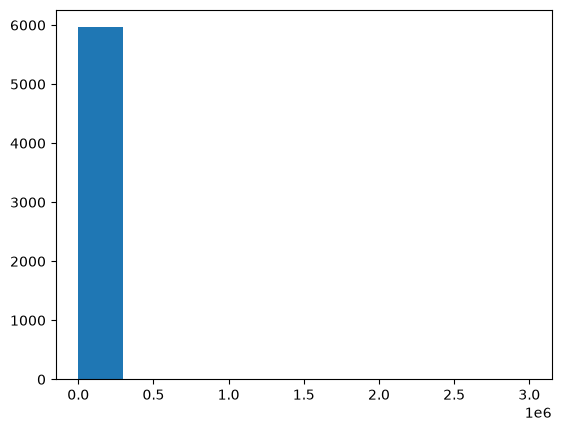

In [45]:
plt.hist(df['weight_kg'])

In [125]:
# plt.hist(df['new_weight'])

(array([   8.,   18.,   58.,  122.,  357.,  624., 1095., 1488., 1325.,
         905.]),
 array([3.4339872 , 3.8719441 , 4.309901  , 4.7478579 , 5.1858148 ,
        5.62377169, 6.06172859, 6.49968549, 6.93764239, 7.37559929,
        7.81355618]),
 <BarContainer object of 10 artists>)

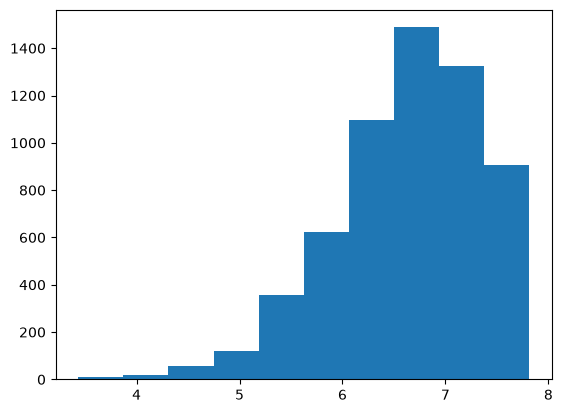

In [47]:
plt.hist(df['weight_log_capped'])

We can see that after applied the algoritmic transformation the distribution for this feature change a lot

In [126]:
print(f'Skew weight_kg:', df['weight_kg'].skew())
print(f'Skew new_weight:', df['new_weight'].skew())
print(f'Skew weight_log_capped:', df['weight_log_capped'].skew())

Skew weight_kg: 18.089335538569884
Skew new_weight: 2.505804685245971
Skew weight_log_capped: -0.6634083402249839


The sked went from extreamly to the right to better distributed to the left

## 7. Feature engineering

### a. Route distance

In [49]:
# df['distance_km'].describe(), we used the information from 25,50 and 75 to stablish the distance categories
#short distance: < 398.475
#medium distance: 398.475 - 804.50
#long distance: > 804.50

df['route_distance'] = pd.qcut(df['distance_km'], 3, labels=['Short', 'Medium', 'Long'])
df['route_distance'].value_counts()

route_distance
Short     2001
Long      2000
Medium    1999
Name: count, dtype: int64

In [50]:
df.groupby('route_distance')['distance_km'].min(), df.groupby('route_distance')['distance_km'].max()

(route_distance
 Short      80.5
 Medium    453.8
 Long      718.0
 Name: distance_km, dtype: float64,
 route_distance
 Short      453.6
 Medium     717.7
 Long      2556.7
 Name: distance_km, dtype: float64)

In [51]:
df.groupby('route_distance')['delivered_late'].mean()

route_distance
Short     0.140430
Medium    0.186593
Long      0.290000
Name: delivered_late, dtype: float64

We can see that the lates deliveries increase if the distance is long. Short shipments have a 14% of delivery rate, meanwhile medium shipment have a 18.65%, and a 29% for long shipments which indicates that if the distance is long there is a high change for the shipment to be delay

### b. Shipment is heavy

In [52]:
#is heavy (1): >1286
#is not heavy (0): <=1286 
df['weight_kg'].describe()

count    6.000000e+03
mean     6.962393e+03
std      8.399790e+04
min      3.000000e+01
25%      4.959750e+02
50%      8.271000e+02
75%      1.286750e+03
max      2.999300e+06
Name: weight_kg, dtype: float64

In [53]:
df['shipment_is_heavy'] = np.where(df['weight_kg'] > 1286.75, 1, 0)

In [54]:
df['shipment_is_heavy'].value_counts()

shipment_is_heavy
0    4500
1    1500
Name: count, dtype: int64

In [55]:
df.groupby('shipment_is_heavy')['delivered_late'].mean()

shipment_is_heavy
0    0.196000
1    0.234667
Name: delivered_late, dtype: float64

We can see that for the shipments that are heavy have a 23% of dely vs the ones that are not heavy with 19%, it suggest that the delay may have be related with the weight

### c. Weather traffic risk

In [56]:
#high_traffic (1) > 67
#low_traffic (0)<= 67 (df['traffic_index'] 75% = 67.000000)
df['high_traffic'] = np.where(df['traffic_index'] > 67, 1, 0)

In [57]:
df['weather_traffic_risk'] = ((df['weather_condition'] != 'Clear') & (df['high_traffic'] == 1)).astype(int)

In [58]:
#weather_traffic_risk (1): weather condition is not clear and traffic is high
#weather_traffic_risk (0): weather condition is clear or traffic is low
df['weather_traffic_risk'].value_counts()

weather_traffic_risk
0    5322
1     678
Name: count, dtype: int64

In [59]:
df.groupby('weather_traffic_risk')['delivered_late'].mean()

weather_traffic_risk
0    0.182074
1    0.390855
Name: delivered_late, dtype: float64

It clearly shows that weather conditions and high traffic have a great impact in the delays with a 39% meanwhile with a clear weather and low traffic have a 18%.

### d. Weather traffic congestion risk

In [60]:
#low_route_congestion (0)<= 0.58 (df['route_congestion_score'] 75% = 67.000000)
#high_route_congestion (1) > 0.58
df['high_route_congestion'] = (df['route_congestion_score'] > 0.583).astype(int)

In [61]:
df['high_route_congestion'].value_counts()

high_route_congestion
0    4508
1    1492
Name: count, dtype: int64

In [62]:
df['weather_traffic_congestion_risk'] = ((df['weather_condition'] != 'Clear') & (df['high_traffic'] == 1) & (df['high_route_congestion'] == 1)).astype(int)

In [63]:
df['weather_traffic_congestion_risk'].value_counts()

weather_traffic_congestion_risk
0    5816
1     184
Name: count, dtype: int64

In [64]:
df['high_route_congestion'].value_counts()

high_route_congestion
0    4508
1    1492
Name: count, dtype: int64

In [65]:
df.groupby('weather_traffic_congestion_risk')['delivered_late'].mean()

weather_traffic_congestion_risk
0    0.198590
1    0.429348
Name: delivered_late, dtype: float64

The shipments that meet the three conditions have a delay rate of 42% vs the rest of the shipments

### e. Weather congestion risk

In [66]:
# low weather_congestion_risk (0): low risk when weather condition is clear, traffic is low or route congestion score is low
# high weather_congestion_risk (1): risk when weather condition is not clear, traffic is high and route congestion score is high
df['weather_congestion_risk'] = ((df['weather_condition'] != 'Clear') & (df['route_congestion_score'] > 0.583)).astype(int)

In [67]:
df['weather_congestion_risk'].value_counts()

weather_congestion_risk
0    5271
1     729
Name: count, dtype: int64

In [68]:
df.groupby('weather_congestion_risk')['delivered_late'].mean()

weather_congestion_risk
0    0.185733
1    0.349794
Name: delivered_late, dtype: float64

The shipments with adverse weather and congestion high have a 34% of delays vs the others

## 8. Data preparation

In [69]:
from sklearn.model_selection import train_test_split

# 1. Separar tus features (X) y tu target (y)
X = df.drop(columns=['delivered_late',
                     'shipment_id',
                     'new_weight', 
                     'weight_capped',
                     'weight_log_capped', 
                     'actual_transit_hours', 
                     'scheduled_transit_hours'])
y = df['delivered_late']

# 2. Dividir en Train y Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4, stratify=y)

In [70]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((4800, 26), (1200, 26), (4800,), (1200,))

In [71]:
X_train.dtypes

origin_city                             str
destination_city                        str
carrier                                 str
service_level                           str
goods_type                              str
customer_priority_tier                  str
shipment_month                        int64
distance_km                         float64
weight_kg                           float64
num_stops                             int64
is_cross_border                       int64
pickup_delay_minutes                float64
driver_experience_years             float64
vehicle_age_years                   float64
weather_condition                       str
traffic_index                       float64
route_congestion_score              float64
prior_late_deliveries_30d             int64
fuel_cost_cad                       float64
route_distance                     category
shipment_is_heavy                     int64
high_traffic                          int64
weather_traffic_risk            

In [72]:
#list of categorical variables
categorical_cols = X_train.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

categorical_cols

['origin_city',
 'destination_city',
 'carrier',
 'service_level',
 'goods_type',
 'customer_priority_tier',
 'weather_condition',
 'route_distance']

In [73]:
#list of numerical variables
numc_cols = X_train.select_dtypes(include=['number']).columns.tolist()
numc_cols

['shipment_month',
 'distance_km',
 'weight_kg',
 'num_stops',
 'is_cross_border',
 'pickup_delay_minutes',
 'driver_experience_years',
 'vehicle_age_years',
 'traffic_index',
 'route_congestion_score',
 'prior_late_deliveries_30d',
 'fuel_cost_cad',
 'shipment_is_heavy',
 'high_traffic',
 'weather_traffic_risk',
 'high_route_congestion',
 'weather_traffic_congestion_risk',
 'weather_congestion_risk']

In [74]:
len(categorical_cols), len(numc_cols)

(8, 18)

## 9. Data modelling

In [75]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

#transformer to scale the numerical variables and one hot encode the categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numc_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [76]:
X_train_processed = preprocessor.fit_transform(X_train) #se utiliza para aprender las transformaciones y aplicarlas al conjunto de entrenamiento.

In [77]:
X_test_processed = preprocessor.transform(X_test) #aplica esas mismas transformaciones al conjunto de prueba, sin volver a aprenderlas.

In [78]:
X_train_processed.shape

(4800, 59)

### a. Logistic Regression

In [79]:
#train a logistic regression model with the processed training data
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

#train the model with the processed training data
lr_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [80]:
X_test_processed = preprocessor.transform(X_test)

y_pred_lr = lr_model.predict(X_test_processed) #threshold of the 0.50

In [81]:
#Adjustment 1
y_prob_lr = lr_model.predict_proba(X_test_processed)[:, 1] #get the probabilities of the positive class (1) for each sample in the test set

In [82]:
from sklearn.metrics import classification_report

y_pred_lr_40 = (y_prob_lr >= 0.40).astype(int) #umbral of the 0.40

print(classification_report(y_test, y_pred_lr_40))

              precision    recall  f1-score   support

           0       0.87      0.92      0.89       953
           1       0.60      0.49      0.54       247

    accuracy                           0.83      1200
   macro avg       0.74      0.70      0.72      1200
weighted avg       0.82      0.83      0.82      1200



In [83]:
#Adjustment 2
y_pred_lr_35 = (y_prob_lr >= 0.35).astype(int)

print(classification_report(y_test, y_pred_lr_35))

              precision    recall  f1-score   support

           0       0.89      0.88      0.88       953
           1       0.55      0.56      0.55       247

    accuracy                           0.81      1200
   macro avg       0.72      0.72      0.72      1200
weighted avg       0.82      0.81      0.82      1200



In [84]:
import pandas as pd

comparison = pd.DataFrame({
    'Threshold': [0.50, 0.40, 0.35],
    'Accuracy': [0.84, 0.83, 0.81],
    'Precision': [0.70, 0.60, 0.55],
    'Recall': [0.39, 0.49, 0.56],
    'F1-score': [0.50, 0.54, 0.55]
})

comparison

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.50,0.84,0.70,0.39,0.50
1,0.40,0.83,0.60,0.49,0.54
2,0.35,0.81,0.55,0.56,0.55


### b. Random Forest

In [96]:
#train a random forest model with the original model data
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

## 10. Model evaluation

### a. Logistc Regression metrics

In [97]:
#evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_lr = lr_model.predict(X_test_processed) 

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.7233333333333334
              precision    recall  f1-score   support

           0       0.79      0.88      0.84       953
           1       0.19      0.11      0.14       247

    accuracy                           0.72      1200
   macro avg       0.49      0.49      0.49      1200
weighted avg       0.67      0.72      0.69      1200



Accuracy: 84%. El modelo clasificó correctamente aproximadamente el 84% de los 1,200 envíos.

Recall de retrasos: 39%. Solo identificó alrededor de 96 de los 247 envíos que realmente llegaron tarde.

Precision de retrasos: 70%. De los envíos que predijo como retrasados, el 70% realmente lo estaba.

### b. Random Forest metrics

In [98]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_rf = rf_model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.7966666666666666
              precision    recall  f1-score   support

           0       0.80      1.00      0.89       953
           1       0.64      0.03      0.05       247

    accuracy                           0.80      1200
   macro avg       0.72      0.51      0.47      1200
weighted avg       0.76      0.80      0.71      1200



## 11. Model explainability

In [ ]:
#%pip install shap

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 6.8 MB/s  0:00:00
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [99]:
import shap

#Make the explainer for the random forest model and calculate the SHAP values for the test set
explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test_processed)

c:\Users\LILIP\Documents\Software Tools\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [100]:
print(type(shap_values))
print(getattr(shap_values, 'shape', 'No tiene shape'))

<class 'numpy.ndarray'>
(1200, 59, 2)


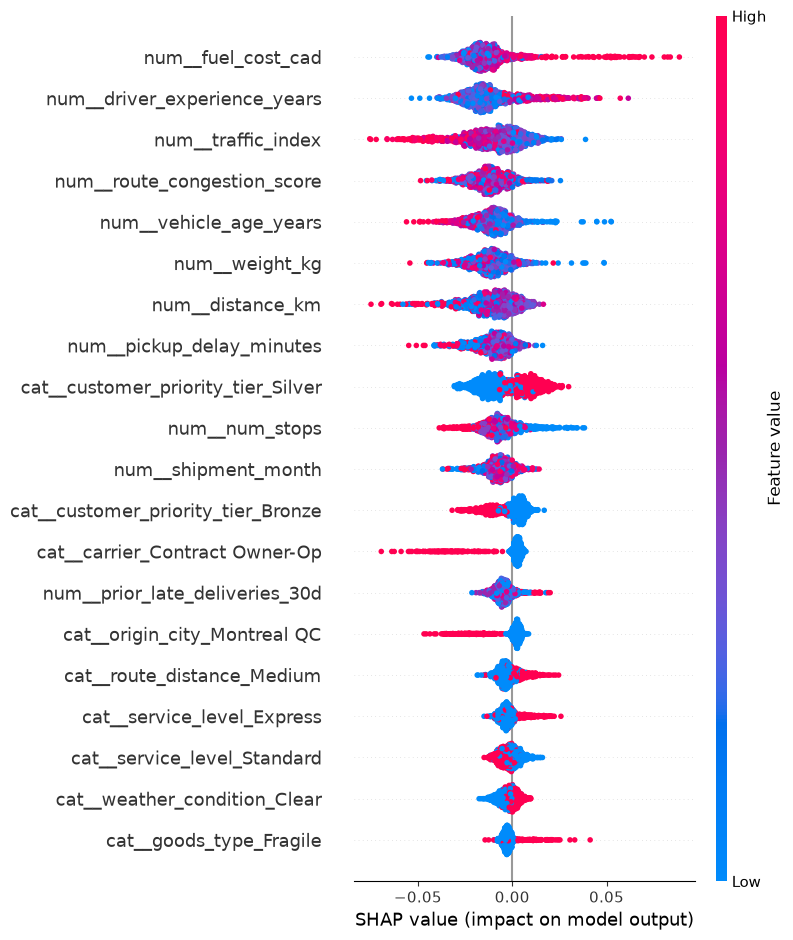

In [101]:
#Make the summary plot for the SHAP values of the random forest model
shap_class1 = shap_values[:, :, 1]

shap.summary_plot(
    shap_class1,
    X_test_processed,
    feature_names=preprocessor.get_feature_names_out()
)

Interpretation

Shap was used on the Random Forest model's predictions. The plot identified that the carrier, number of stops, shipment distance, pickup delay, traffic index and route congestion as features that contributed or influenced the model. 

Major values of number of stops, distance, pickup delay, and traffic index increase the possibility for the predictions to push towards the late delivery, as well as the weather conditions and the carrier category have an effect on it. The foregoing suggest that the shipment complexity, pickup delays, and traffic conditions should be considered to identify high risk shipments.

## 12. Slack alert integration

In [102]:
# Obtener probabilidades de retraso
y_prob_full = rf_model.predict_proba(X_test_processed)[:, 1]

# Crear una tabla con los resultados
alerts = X_test.copy()
alerts['late_probability'] = y_prob_full

# Identificar envíos de alto riesgo
alerts['high_risk'] = alerts['late_probability'] >= 0.35

# Mostrar los envíos de alto riesgo
alerts[alerts['high_risk']].head()

,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,...,fuel_cost_cad,route_distance,shipment_is_heavy,high_traffic,weather_traffic_risk,high_route_congestion,weather_traffic_congestion_risk,weather_congestion_risk,late_probability,high_risk
5395,Montreal QC,Toronto ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,846.2,1140.2,5,...,189.21,Long,0,0,0,0,0,0,0.40,True
3150,Mississauga ON,Toronto ON,MapleFreight Fleet,Economy,Fragile,Gold,7,342.7,547.4,5,...,257.30,Short,0,1,0,0,0,0,0.42,True
1088,Calgary AB,Quebec City QC,NorthStar Carriers,Standard,General Freight,Bronze,2,843.0,361.9,1,...,295.16,Long,0,0,0,0,0,0,0.47,True
2560,London ON,Ottawa ON,PrairieLine,Standard,Fragile,Silver,11,526.7,1848.9,1,...,215.68,Medium,1,1,0,0,0,0,0.41,True
3711,Ottawa ON,Regina SK,QuebecExpress,Standard,General Freight,Bronze,12,778.7,1234.7,4,...,283.51,Long,0,0,0,0,0,0,0.55,True


In [118]:
# Seleccionar el primer envío de alto riesgo
# shipment = alerts[alerts['high_risk']].iloc[0]

# # Crear el mensaje de alerta
# message = f"""
# 🚨 HIGH-RISK SHIPMENT ALERT

# Route: {shipment['origin_city']} → {shipment['destination_city']}
# Carrier: {shipment['carrier']}
# Service: {shipment['service_level']}
# Distance: {shipment['distance_km']} km
# Predicted probability of delay: {shipment['late_probability']:.1%}

# Recommended action: Review the shipment and assess whether
# rerouting or customer notification is needed.
# """

# print(message)

In [119]:
priority_shipments = alerts[
    alerts['late_probability'] >= 0.42
].copy()

priority_shipments = priority_shipments.copy()

priority_shipments['shipment_id'] = df.loc[
    priority_shipments.index, 'shipment_id'
]

In [122]:
shipment = priority_shipments.loc[
    priority_shipments['late_probability'].idxmax()
]

In [ ]:
#%pip install python-dotenv
#Test for the slack alerts
from dotenv import load_dotenv
import os
import requests
import time

# Replace with your actual webhook URL
load_dotenv(dotenv_path="slack_url.env", override=True)

WEBHOOK_URL = os.getenv("SLACK_WEBHOOK_URL")

if not WEBHOOK_URL:
    raise ValueError("Webhook not found. Check your .env file.")

# Select the 5 highest-risk shipments
test_shipments = priority_shipments.nlargest(
    5, 'late_probability'
)

for _, shipment in test_shipments.iterrows():

    message = f"""
🚨 HIGH-RISK SHIPMENT ALERT

Shipment ID: {shipment['shipment_id']}
Route: {shipment['origin_city']} → {shipment['destination_city']}
Carrier: {shipment['carrier']}
Service: {shipment['service_level']}
Predicted probability of delay: {shipment['late_probability']:.1%}

Recommended action: Prioritize dispatch review and assess
rerouting options or customer notification.
"""

    response = requests.post(
        WEBHOOK_URL,
        json={"text": message},
        timeout=10
    )

    response.raise_for_status()

    print(
        f"Alert sent: {shipment['shipment_id']} "
        f"({shipment['late_probability']:.1%})"
    )

    time.sleep(2)

Alert sent: SHP-101749 (53.0%)


In [ ]:
#Automation of the high risk shipments
from dotenv import load_dotenv
import os
import requests
import time


# Replace with your actual webhook URL
load_dotenv(dotenv_path="slack_url.env", override=True)

WEBHOOK_URL = os.getenv("SLACK_WEBHOOK_URL")

if not WEBHOOK_URL:
    raise ValueError("Webhook not found. Check your .env file.")

# Select the highest-risk shipments
shipments_to_alert = priority_shipments.sort_values(
    'late_probability', ascending=False
)

sent_count = 0

for _, shipment in shipments_to_alert.iterrows(): 
    message = f"""
🚨 HIGH-RISK SHIPMENT ALERT

Shipment ID: {shipment['shipment_id']}
Route: {shipment['origin_city']} → {shipment['destination_city']}
Carrier: {shipment['carrier']}
Service: {shipment['service_level']}
Predicted probability of delay: {shipment['late_probability']:.1%}

Recommended action: Prioritize dispatch review and assess
rerouting options or customer notification.
"""

    response = requests.post(
    WEBHOOK_URL,
    json={"text": message},
    timeout=10
    )

    response.raise_for_status()
    sent_count += 1

    print(f"Alert {sent_count}/{len(shipments_to_alert)} sent")

    time.sleep(2)
print(f"Finished: {sent_count} alerts sent.")

Slack integration/automation

The models were used to estimate the probabilities of delays on the shipments. Shipments with a predicted delay of 42% or more were the ones selected to prioritize.

A slack incomming webhook was integrated with python to send automaed notifications when the shipments with risk of delays are identify.

The initial test successfully sent five alerts and then the automation was extend for the totally of shipment delays (146) as a high priority.

This integration helps to demostrate how the predictions can support the dispatch decisions and actions.

## 13. Recommendations

Considering the results of the model and the results from the shap graph, we recommend that MapleFreight the following:

1. Monitoring the pickup delays: could prioritize the shipments with pickup delays, and notify dispatch so a corrective action can be perform.
2. Evaluate the routes: review the shipments with many number of stops or long distances to recognize chances to optimized the route.
3. Traffic and weather conditions: check high traffic, congested routes and the weather conditions to review the alternative routes, and notify the customers in advance so the will know that the shipment will be delay.

This will help MapleFreight recognize shipments at risk, improve dispacth decisions, and reduce the late deliveries.